# Knowing When to Defer: An Ordinal Evidential Involution–Attention Network for Calibrated Knee Osteoarthritis Grading

## 06 — Can it run where radiographs are read?

**What we can test is cost.** Parameters, GFLOPs and wall-clock latency on GPU and CPU, with the
sampling methods costed at their true multiple — MC dropout at 20 passes, an ensemble at M models.

### Setup

Mount Drive so results survive a disconnect, then load the module.

In [ ]:
# --- Colab bootstrap: run this first in every notebook ---------------------
import os, sys, glob, shutil

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = True        # True = results survive a disconnect. False = faster, but temporary.

if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = "/content/drive/MyDrive/EvIA_Knee"
elif IN_COLAB:
    PROJECT = "/content/EvIA_Knee"
else:
    PROJECT = os.path.abspath(".")

os.makedirs(PROJECT, exist_ok=True)
sys.path.insert(0, PROJECT)          # so `import evia_knee` finds the module written by 00
CACHE = os.path.join(PROJECT, "cache")
print("project:", PROJECT)

Mounted at /content/drive
project: /content/drive/MyDrive/EvIA_Knee


In [ ]:
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print("TF", tf.__version__, "| GPU:", len(gpus))
if not gpus:
    print("  !! No GPU. Runtime > Change runtime type > T4 GPU, then re-run.")

TF 2.21.0 | GPU: 1


In [ ]:
import os, sys, json, time
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

import evia_knee as E
assert hasattr(E.Config(), "lr_schedule"), \
    "Old evia_knee.py loaded. Run 00_core, then Runtime > Restart session."
print("evia_knee:", E.__file__, "| lr schedule", E.Config().lr_schedule)
import evia_viz as V                 # figure style, written by notebook 00
V.use()                # written by notebook 00, found via PROJECT on sys.path
from evia_knee import Config

if IN_COLAB and not os.path.isdir("/content/knee"):
    !pip -q install kaggle
    E.download_kaggle("knee", "/content/knee")
root = E.find_dataset("knee")
print("knee data at:", root)
for d in sorted({os.path.dirname(p)
                 for p in glob.glob(root + "/**/*.png", recursive=True)}):
    print(f"  {os.path.basename(d):14s} {len(glob.glob(d + '/*.png')):5d} images")
print("\nKL1 vs KL2 is the boundary that decides definite OA, and the one "
      "readers disagree on most.")

print("task      :", "knee OA, Kellgren-Lawrence grade 0-4")
print("grades    :", E.GRADE_NAMES)
print("decision  : KL >=", E.OA_THRESHOLD, "=", E.OA_NAME)

# One config object drives everything. Changing a field here changes the experiment.
CFG = Config(
    img_size=224,                  # the radiographs are native ~224 px; upsampling adds nothing
    preprocess="clahe",
    backbone="densenet121",        # full ImageNet DenseNet-121 + EvIA side branch
    widths=(256, 320),             # EvIA branch blocks at 14x14 and 7x7
    global_branch="window",        # EvIA-W
    gate="vacuity",                # parameter-free gate
    operator="evi",
    head="ordinal",
    epochs=60,                     # cosine schedule: every run trains exactly 60 epochs
    batch_size=32,                 # 224 px radiographs leave room for a large batch
    seeds=(42, 43, 44, 45, 46),    # set to (42,) for a quick first pass
    out_dir=os.path.join(PROJECT, "results"),
)
os.makedirs(CFG.out_dir, exist_ok=True)
print("results ->", CFG.out_dir)

evia_knee: /content/drive/MyDrive/EvIA_Knee/evia_knee.py | lr schedule cosine
kaggle datasets download -d shashwatwork/knee-osteoarthritis-dataset-with-severity -p /content/knee
unzipping knee-osteoarthritis-dataset-with-severity.zip
registered DATA_ROOTS['knee'] = /content/knee
knee data at: /content/knee
  0                604 images
  1                275 images
  2                403 images
  3                200 images
  4                 44 images
  0                639 images
  1                296 images
  2                447 images
  3                223 images
  4                 51 images
  0               2286 images
  1               1046 images
  2               1516 images
  3                757 images
  4                173 images
  0                328 images
  1                153 images
  2                212 images
  3                106 images
  4                 27 images

KL1 vs KL2 is the boundary that decides definite OA, and the one readers disagree on most.


In [ ]:
ds = E.load_knee(cfg=CFG, seed=42)
idx = ds["idx"]
print(f"{ds['name']}: {len(ds['y'])} images")
print("  grades    :", np.bincount(ds["y"], minlength=5))
print(f"  definite OA : {(ds['y']>=E.OA_THRESHOLD).sum()} "
      f"({(ds['y']>=E.OA_THRESHOLD).mean():.1%})")

# Decoded once into uint8 arrays and cached. A restarted session reloads in seconds.
data = {k: E.cached_split(ds["paths"][idx[k]], ds["y"][idx[k]], CFG, "knee_" + k, CACHE)
        for k in ("train", "val", "test")}
Xte, Yte = data["test"]
print(" ", {k: f"{v[0].shape} {v[0].dtype}" for k, v in data.items()})

  using the dataset's own train/val/test split
Knee OA (KL 0-4): 9786 images
  grades    : [3857 1770 2578 1286  295]
  definite OA : 4159 (42.5%)
  knee_train: loaded from cache
  knee_val: loaded from cache
  knee_test: loaded from cache
  {'train': '(5778, 224, 224, 3) uint8', 'val': '(826, 224, 224, 3) uint8', 'test': '(1656, 224, 224, 3) uint8'}


In [ ]:
# There is no second public cohort with KL grades and comparable acquisition, so this
# study reports internal validation only. State it; do not quietly omit it.
print("external validation : not available")
print("                      no second public KL-graded cohort exists")
print("                      -> goes in Limitations and in the abstract")

external validation : not available
                      no second public KL-graded cohort exists
                      -> goes in Limitations and in the abstract


### 1. Efficiency

In [ ]:
eff = []
m = E.EvIAKL(CFG); _ = m(tf.zeros([1, CFG.img_size, CFG.img_size, 3]))
eff.append(dict(model="EvIA-KL", passes=1, params=E.count_params(m),
                gflops=E.estimate_flops(m, CFG), **E.measure_latency(m, CFG, batch=1)))
del m; keras.backend.clear_session()

for n in ["mobilenetv3s", "efficientnetb0", "densenet121", "resnet50"]:
    b = E.build_baseline(n, CFG)
    eff.append(dict(model=n, passes=1, params=E.count_params(b),
                    gflops=E.estimate_flops(b, CFG), **E.measure_latency(b, CFG, batch=1)))
    del b; keras.backend.clear_session()

EFF = pd.DataFrame(eff)
EFF["params_M"] = (EFF["params"] / 1e6).round(2)
EFF.to_csv(os.path.join(CFG.out_dir, "efficiency.csv"), index=False)
print(EFF[["model","params_M","gflops","latency_ms_mean","latency_ms_p95"]].round(3)
         .to_string(index=False))

# true cost of ONE uncertainty estimate
print("\nTRUE COST OF AN UNCERTAINTY ESTIMATE")
base = EFF[EFF.model == "efficientnetb0"].latency_ms_mean.iloc[0]
evia = EFF[EFF.model == "EvIA-KL"].latency_ms_mean.iloc[0]
for name, mult in [("EvIA-KL (closed form)", 1), ("softmax + temperature", 1),
                   ("MC dropout (T=20)", 20), ("deep ensemble (M=3)", 3)]:
    cost = evia if name.startswith("EvIA") else base * mult
    print(f"  {name:24s} {cost:7.1f} ms  ({mult} pass{'es' if mult > 1 else ''})")

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.


4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
         model  params_M  gflops  latency_ms_mean  latency_ms_p95
       EvIA-KL      8.72   6.116           19.235          26.197
  mobilenetv3s      0.93   0.116            4.792           4.885
efficientnetb0      4.01   0.801            6.901           7.068
   densenet121      6.96   5.701           16.053          17.223
      resnet50     23.54   7.752            8.071           9.878

TRUE COST OF AN UNCERTAINTY ESTIMATE
  EvIA-KL (closed form)       19.2 ms  (1 pass)
  softmax + temperature        6.9 ms  (1 pass)
  MC dropout (T=20)          138.0 ms  (20 passes)
  deep ensemble (M=3)         20.7 ms  (3 passes)


In [ ]:
# CPU latency decides point-of-care feasibility.
with tf.device("/CPU:0"):
    m = E.EvIAKL(CFG); _ = m(tf.zeros([1, CFG.img_size, CFG.img_size, 3]))
    c_evia = E.measure_latency(m, CFG, n_rep=15); del m; keras.backend.clear_session()
    cpu = {}
    for n in ["densenet121", "efficientnetb0", "resnet50"]:
        b = E.build_baseline(n, CFG)
        cpu[n] = E.measure_latency(b, CFG, n_rep=15); del b; keras.backend.clear_session()

print(f"CPU  EvIA-KL         {c_evia['latency_ms_mean']:7.1f} ms (p95 {c_evia['latency_ms_p95']:.1f})")
for n, r in cpu.items():
    print(f"CPU  {n:15s} {r['latency_ms_mean']:7.1f} ms (p95 {r['latency_ms_p95']:.1f})")
c_r50 = cpu["resnet50"]
print(f"\nMC dropout (T=20) on EfficientNet-B0 would need "
      f"{20*cpu['efficientnetb0']['latency_ms_mean']/1000:.2f} s per image on this CPU; "
      f"a deep ensemble (M=3) {3*cpu['efficientnetb0']['latency_ms_mean']/1000:.2f} s.")

CPU  EvIA-KL            55.4 ms (p95 57.7)
CPU  densenet121        54.2 ms (p95 56.8)
CPU  efficientnetb0     33.6 ms (p95 36.8)
CPU  resnet50           38.6 ms (p95 41.0)

MC dropout (T=20) on EfficientNet-B0 would need 0.67 s per image on this CPU; a deep ensemble (M=3) 0.10 s.


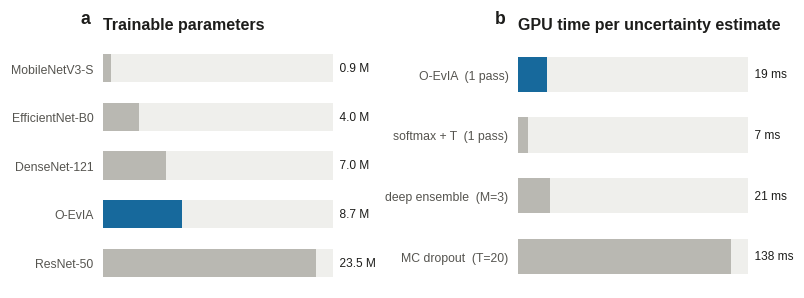

'/content/drive/MyDrive/EvIA_Knee/results/fig_efficiency.png'

In [ ]:
NAMES = {"EvIA-KL": "O-EvIA", "mobilenetv3s": "MobileNetV3-S", "efficientnetb0": "EfficientNet-B0",
         "densenet121": "DenseNet-121", "resnet50": "ResNet-50"}
fig, ax = V.figure(1, 2, width=7.2, height=2.6)
V.track_barh(ax[0], [NAMES.get(m, m) for m in EFF.model], EFF.params_M.values,
             colors=[V.OURS if m == "EvIA-KL" else V.COMPARATOR for m in EFF.model],
             value_fmt="{:.1f} M", order="asc")
ax[0].set_title("Trainable parameters")

cost = [("O-EvIA  (1 pass)", evia, V.OURS), ("softmax + T  (1 pass)", base, V.COMPARATOR),
        ("deep ensemble  (M=3)", 3 * base, V.COMPARATOR),
        ("MC dropout  (T=20)", 20 * base, V.COMPARATOR)]
V.track_barh(ax[1], [c[0] for c in cost], [c[1] for c in cost], colors=[c[2] for c in cost],
             value_fmt="{:.0f} ms")
ax[1].set_title("GPU time per uncertainty estimate")
V.panel_letters(ax)
V.save(fig, "fig_efficiency", CFG.out_dir)

### 2. Final table

In [ ]:
try:
    G = pd.read_csv(os.path.join(CFG.out_dir, "grading_all.csv"))
    R = pd.read_csv(os.path.join(CFG.out_dir, "deferral.csv"))
    CA = pd.read_csv(os.path.join(CFG.out_dir, "calibration.csv"))
    ev = G[G.tag == "EvIA-KL"]; tg = R[R.signal == "targeted u_ref"]
    final = pd.DataFrame([
        ("QWK (held-out test)",          f"{ev.qwk.mean():.3f} ± {ev.qwk.std():.3f}"),
        ("Definite-OA AUC",              f"{ev.oa_auc.mean():.3f} ± {ev.oa_auc.std():.3f}"),
        ("ECE",                          f"{CA[CA.tag=='EvIA-KL'].ece.mean():.3f}"),
        ("Coverage @ 90% sensitivity",   f"{tg.coverage_at_sens90.mean():.1%}"),
        ("Human workload @ 90%",         f"{1-tg.coverage_at_sens90.mean():.1%}"),
        ("Parameters",                   f"{EFF[EFF.model=='EvIA-KL'].params_M.iloc[0]:.2f} M"),
        ("CPU latency per image",        f"{c_evia['latency_ms_mean']:.0f} ms"),
        ("Passes for uncertainty",       "1"),
    ], columns=["item", "value"])
    final.to_csv(os.path.join(CFG.out_dir, "final_table.csv"), index=False)
    print(final.to_string(index=False))
except Exception as ex:
    print("Run notebooks 02-04 first:", ex)

                      item         value
       QWK (held-out test) 0.821 ± 0.052
           Definite-OA AUC 0.929 ± 0.021
                       ECE         0.052
Coverage @ 90% sensitivity         63.0%
      Human workload @ 90%         37.0%
                Parameters        8.72 M
     CPU latency per image         55 ms
    Passes for uncertainty             1
